# ch03_3. Softmax 다중분류

## A·B·C 클래스 중 하나 예측하기

## 개요

- Binary Classification(바이너리 클래시피케이션, 이진분류)을 3개 클래스 분류로 확장합니다.
- 정확도·클래스별 확률·혼동행렬을 확인합니다.

## 1. 이진분류와 다중분류 비교

| 구분 | 이진분류 | 다중분류 |
|---|---|---|
| 클래스 수 | 2개 | 3개 이상 |
| 모델 출력 | 로짓 1개 | 클래스 수만큼 로짓 |
| 확률 변환 | Sigmoid(시그모이드) | Softmax(소프트맥스) |
| 손실함수 | `BCEWithLogitsLoss()` | `CrossEntropyLoss()` |
| 정답 형식 | `[N, 1]`, 실수형 | `[N]`, 정수형 |
| 최종 예측 | 임계값 비교 | `argmax()` |

입력 특성 4개로 A·B·C 중 하나를 예측합니다.

## 2. 라이브러리와 데이터 준비

- 데이터 수: 8개
- 입력 특성 수: 4개
- 클래스 수: 3개
- 클래스 번호: `0`, `1`, `2`
- 클래스 이름: A, B, C

각 행은 데이터 하나이며, 정답은 클래스 번호 하나로 저장합니다.

In [1]:
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

x_data = torch.tensor(
    [
        [1.0, 2.0, 1.0, 1.0],
        [2.0, 1.0, 3.0, 2.0],
        [3.0, 1.0, 3.0, 4.0],
        [4.0, 1.0, 5.0, 5.0],
        [1.0, 7.0, 5.0, 5.0],
        [1.0, 2.0, 5.0, 6.0],
        [1.0, 6.0, 6.0, 6.0],
        [1.0, 7.0, 7.0, 7.0],
    ],
    dtype=torch.float32,
)

# 0 → A, 1 → B, 2 → C
y_data = torch.tensor(
    [2, 2, 2, 1, 1, 1, 0, 0],
    dtype=torch.long,
)

class_names = ["A", "B", "C"]
number_of_classes = len(class_names)

print("입력 shape:", x_data.shape)
print("정답 shape:", y_data.shape)
print("정답 자료형:", y_data.dtype)

입력 shape: torch.Size([8, 4])
정답 shape: torch.Size([8])
정답 자료형: torch.int64


## 3. 클래스 인덱스와 원핫 벡터

| 클래스 | 클래스 인덱스 | 원핫 벡터 |
|---|---:|---|
| A | `0` | `[1, 0, 0]` |
| B | `1` | `[0, 1, 0]` |
| C | `2` | `[0, 0, 1]` |

원핫 벡터는 구조를 이해할 때 유용합니다.

하지만 `CrossEntropyLoss()`에는 원핫 벡터가 아니라 다음 형식의 클래스 인덱스를 전달합니다.

- shape: `[데이터 수]`
- 자료형: `torch.long`

In [2]:
y_one_hot = F.one_hot(
    y_data,
    num_classes=number_of_classes,
)

print("클래스 인덱스:")
print(y_data)

print()
print("원핫 벡터:")
print(y_one_hot)

클래스 인덱스:
tensor([2, 2, 2, 1, 1, 1, 0, 0])

원핫 벡터:
tensor([[0, 0, 1],
        [0, 0, 1],
        [0, 0, 1],
        [0, 1, 0],
        [0, 1, 0],
        [0, 1, 0],
        [1, 0, 0],
        [1, 0, 0]])


## 4. 클래스별 로짓

다중분류 모델은 데이터마다 클래스 수만큼 로짓을 계산합니다.

$$
Z=XW^T+b
$$

입력 특성이 4개이고 클래스가 3개이면 다음 구조가 됩니다.

$$
[x_1,x_2,x_3,x_4]
\rightarrow
[z_A,z_B,z_C]
$$

- $z_A$: A 클래스의 로짓
- $z_B$: B 클래스의 로짓
- $z_C$: C 클래스의 로짓

로짓은 아직 확률이 아닙니다.

## 5. Softmax로 확률 계산

Softmax는 클래스별 로짓을 0과 1 사이의 확률로 변환합니다.

$$
P(y=k|x)
=
\frac{e^{z_k}}
{\sum_{j=1}^{K}e^{z_j}}
$$

한 데이터의 모든 클래스 확률을 더하면 1이 됩니다.

In [3]:
example_logits = torch.tensor(
    [
        [2.0, 1.0, 0.1],
        [-1.0, 0.5, 2.5],
    ],
    dtype=torch.float32,
)

# dim=1: 각 행의 A·B·C 로짓을 확률로 변환
example_probabilities = torch.softmax(
    example_logits,
    dim=1,
)

print("로짓:")
print(example_logits)

print()
print("Softmax 확률:")
print(example_probabilities)

print()
print("행별 확률 합:")
print(example_probabilities.sum(dim=1))

print()
print("예측 클래스 번호:")
print(torch.argmax(example_probabilities, dim=1))

로짓:
tensor([[ 2.0000,  1.0000,  0.1000],
        [-1.0000,  0.5000,  2.5000]])

Softmax 확률:
tensor([[0.6590, 0.2424, 0.0986],
        [0.0259, 0.1161, 0.8580]])

행별 확률 합:
tensor([1.0000, 1.0000])

예측 클래스 번호:
tensor([0, 2])


## 6. `dim=1`의 의미

`example_logits`의 shape는 `[2, 3]`입니다.

- `2`: 데이터 수
- `3`: A·B·C 클래스 수

Softmax는 **각 데이터 안에서 클래스끼리 비교**해야 하므로 `dim=1`을 사용합니다.

```python
torch.softmax(logits, dim=1)
```

`dim=1`을 적용하면 각 행의 확률 합이 1이 됩니다.

## 7. 교차엔트로피 손실

정답 클래스의 예측 확률을 $p_{\mathrm{correct}}$라고 하면 데이터 하나의 손실은 다음과 같습니다.

$$
\mathrm{Loss}
=
-\log(p_{\mathrm{correct}})
$$

- 정답 클래스 확률이 높음 → 손실이 작음
- 정답 클래스 확률이 낮음 → 손실이 큼
- 틀린 클래스를 높은 확률로 예측 → 큰 손실

아래에서는 첫 번째 데이터의 손실을 직접 계산하고 PyTorch 결과와 비교합니다.

In [4]:
first_logit = example_logits[0:1]
first_target = torch.tensor([0])

first_probability = torch.softmax(
    first_logit,
    dim=1,
)

correct_probability = first_probability[0, 0]
manual_loss = -torch.log(correct_probability)

loss_function = nn.CrossEntropyLoss()
pytorch_loss = loss_function(
    first_logit,
    first_target,
)

print("정답 클래스 확률:", correct_probability.item())
print("직접 계산한 Loss:", manual_loss.item())
print("CrossEntropyLoss:", pytorch_loss.item())

정답 클래스 확률: 0.6590011715888977
직접 계산한 Loss: 0.4170299768447876
CrossEntropyLoss: 0.4170299470424652


## 8. `CrossEntropyLoss()` 사용 기준

`CrossEntropyLoss()`는 내부에서 다음 계산을 함께 처리합니다.

```text
LogSoftmax
→ Negative Log Likelihood
→ 평균 손실
```

따라서 학습할 때는 모델 출력 로짓에 Softmax를 먼저 적용하지 않습니다.

```python
# 올바른 사용
loss = loss_function(logits, targets)

# 사용하지 않음
loss = loss_function(torch.softmax(logits, dim=1), targets)
```

Softmax는 학습이 끝난 뒤 확률을 확인할 때 사용합니다.

## 9. 다중분류 모델

입력 특성 4개로 클래스별 로짓 3개를 출력하므로 다음 선형 계층을 사용합니다.

```python
nn.Linear(4, 3)
```

별도의 모델 클래스를 만들지 않고 선형 계층 하나를 직접 사용합니다.

In [5]:
torch.manual_seed(42)

model = nn.Linear(4, 3)

print(model)
print("가중치 shape:", model.weight.shape)
print("편향 shape:", model.bias.shape)

initial_logits = model(x_data)
print("모델 출력 shape:", initial_logits.shape)

Linear(in_features=4, out_features=3, bias=True)
가중치 shape: torch.Size([3, 4])
편향 shape: torch.Size([3])
모델 출력 shape: torch.Size([8, 3])


## 10. 모델 학습

학습 흐름은 와 같습니다.

$$
\text{로짓 계산}
\rightarrow
\text{손실 계산}
\rightarrow
\text{역전파}
\rightarrow
\text{가중치 갱신}
$$

`CrossEntropyLoss()`를 사용하고, 정답은 클래스 인덱스로 전달합니다.

In [6]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
)

epochs = 2000
loss_history = []

model.train()

for epoch in range(epochs):
    # 1. 클래스별 로짓 계산
    logits = model(x_data)

    # 2. 교차엔트로피 손실 계산
    loss = loss_function(
        logits,
        y_data,
    )

    # 3. 이전 기울기 초기화
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치와 편향 갱신
    optimizer.step()

    loss_history.append(loss.item())

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

처음 Loss: 2.035637855529785
마지막 Loss: 0.1611168533563614


## 11. 손실 변화 확인

학습이 진행되면서 Cross Entropy Loss(크로스 엔트로피 로스, 교차엔트로피 손실)가 감소하는지 확인합니다.

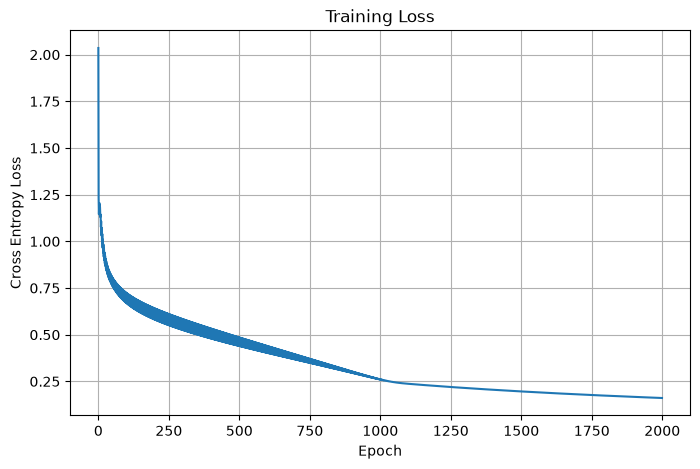

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("Training Loss")
plt.grid()
plt.show()

## 12. 확률·예측 클래스·정확도 확인

학습이 끝난 뒤 결과를 다음 순서로 해석합니다.

$$
\text{Logit}
\rightarrow
\text{Softmax Probability}
\rightarrow
\text{argmax}
\rightarrow
\text{Predicted Class}
$$

`argmax(dim=1)`은 각 데이터에서 가장 큰 로짓의 클래스 번호를 반환합니다.

Softmax는 로짓의 순서를 바꾸지 않으므로 클래스 예측에는 로짓에 바로 `argmax()`를 적용할 수 있습니다.

In [8]:
model.eval()

with torch.no_grad():
    trained_logits = model(x_data)

    trained_probabilities = torch.softmax(
        trained_logits,
        dim=1,
    )

    predicted_classes = torch.argmax(
        trained_logits,
        dim=1,
    )

    accuracy = (
        predicted_classes == y_data
    ).float().mean()

print(f"학습 데이터 정확도: {accuracy.item():.4f}")

print()
print("번호 | 확률 [A, B, C]               | 예측 | 실제")

for index in range(len(x_data)):
    probabilities = trained_probabilities[index]
    predicted = predicted_classes[index].item()
    actual = y_data[index].item()

    probability_list = [
        round(value, 4)
        for value in probabilities.tolist()
    ]

    print(
        f"{index:>4d} | "
        f"{str(probability_list):<29} | "
        f"{class_names[predicted]:>4s} | "
        f"{class_names[actual]:>4s}"
    )

학습 데이터 정확도: 1.0000

번호 | 확률 [A, B, C]               | 예측 | 실제
   0 | [0.0, 0.0013, 0.9987]         |    C |    C
   1 | [0.0013, 0.0831, 0.9156]      |    C |    C
   2 | [0.0, 0.1665, 0.8335]         |    C |    C
   3 | [0.0, 0.8481, 0.1519]         |    B |    B
   4 | [0.2635, 0.7242, 0.0123]      |    B |    B
   5 | [0.1388, 0.8612, 0.0]         |    B |    B
   6 | [0.7461, 0.2539, 0.0]         |    A |    A
   7 | [0.9166, 0.0834, 0.0]         |    A |    A


## 13. 클래스별 확률 시각화

- 가로축: 클래스 A·B·C
- 세로축: 데이터 번호
- 셀의 값: 해당 클래스의 예측 확률

각 행에서 가장 큰 값의 클래스가 최종 예측입니다.

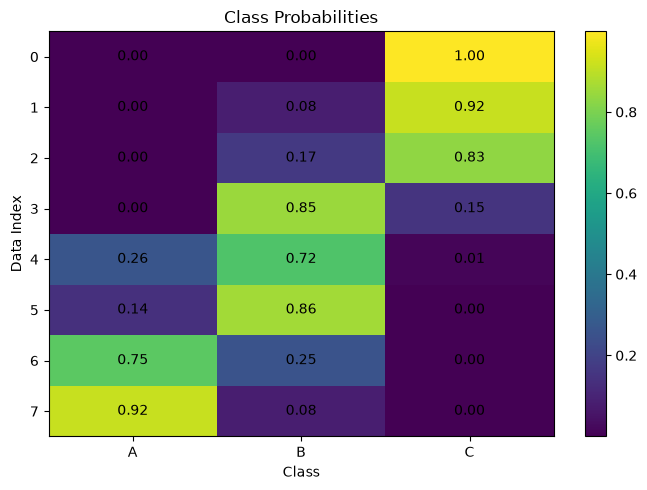

In [9]:
plt.figure(figsize=(7, 5))
plt.imshow(
    trained_probabilities.numpy(),
    aspect="auto",
)

plt.xticks(
    range(number_of_classes),
    class_names,
)

plt.yticks(
    range(len(x_data)),
    range(len(x_data)),
)

plt.xlabel("Class")
plt.ylabel("Data Index")
plt.title("Class Probabilities")
plt.colorbar()

for row in range(len(x_data)):
    for column in range(number_of_classes):
        value = trained_probabilities[
            row,
            column,
        ].item()

        plt.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
        )

plt.tight_layout()
plt.show()

## 14. 다중분류 혼동행렬

- 행: 실제 클래스
- 열: 예측 클래스
- 대각선: 올바르게 분류한 데이터
- 대각선 밖: 다른 클래스로 잘못 분류한 데이터

현재 데이터는 8개뿐이므로 일반화 성능이 아니라 학습 데이터 적합도를 확인하는 예제입니다.

혼동행렬:
tensor([[2, 0, 0],
        [0, 3, 0],
        [0, 0, 3]])


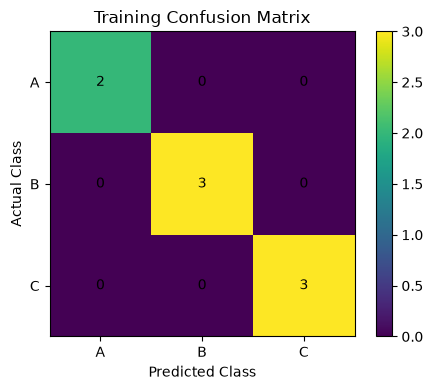

In [10]:
confusion_matrix = torch.zeros(
    number_of_classes,
    number_of_classes,
    dtype=torch.int64,
)

for actual, predicted in zip(
    y_data,
    predicted_classes,
):
    confusion_matrix[actual, predicted] += 1

print("혼동행렬:")
print(confusion_matrix)

plt.figure(figsize=(5, 4))
plt.imshow(confusion_matrix.numpy())

plt.xticks(
    range(number_of_classes),
    class_names,
)

plt.yticks(
    range(number_of_classes),
    class_names,
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Training Confusion Matrix")

for row in range(number_of_classes):
    for column in range(number_of_classes):
        plt.text(
            column,
            row,
            int(confusion_matrix[row, column]),
            ha="center",
            va="center",
        )

plt.colorbar()
plt.tight_layout()
plt.show()

## 15. 새로운 데이터 예측

새로운 데이터도 입력 특성 4개를 가져야 합니다.

예측 순서:

1. 모델로 로짓 3개 계산
2. Softmax로 A·B·C 확률 확인
3. `argmax()`로 가장 큰 클래스 선택

In [11]:
new_x = torch.tensor(
    [
        [1.0, 5.0, 5.0, 5.0],
        [3.0, 2.0, 4.0, 4.0],
        [2.0, 1.0, 2.0, 2.0],
    ],
    dtype=torch.float32,
)

model.eval()

with torch.no_grad():
    new_logits = model(new_x)

    new_probabilities = torch.softmax(
        new_logits,
        dim=1,
    )

    new_predictions = torch.argmax(
        new_logits,
        dim=1,
    )

print("입력                  | 확률 [A, B, C]             | 예측")

for inputs, probabilities, predicted in zip(
    new_x,
    new_probabilities,
    new_predictions,
):
    probability_list = [
        round(value, 4)
        for value in probabilities.tolist()
    ]

    print(
        f"{str(inputs.tolist()):<21} | "
        f"{str(probability_list):<27} | "
        f"{class_names[predicted.item()]}"
    )

입력                  | 확률 [A, B, C]             | 예측
[1.0, 5.0, 5.0, 5.0]  | [0.4395, 0.559, 0.0015]     | B
[3.0, 2.0, 4.0, 4.0]  | [0.0, 0.3987, 0.6013]       | C
[2.0, 1.0, 2.0, 2.0]  | [0.0, 0.0107, 0.9893]       | C


## 17. 핵심 정리

- 다중분류는 세 개 이상의 클래스 중 하나를 예측합니다.
- 한 데이터의 클래스 확률 합은 1입니다.
- 현재 정확도는 작은 학습 데이터의 적합도이며 일반화 성능은 아닙니다.